# Two ways to build the Pac-Man maze

<!-- index:description -->
Build the [Pac-Man](https://en.wikipedia.org/wiki/Pac-Man) maze with CSG corridors with `RectLattice`, and export the geometries for reuse in future variance reduction notebooks.
<!-- /index:description -->

<!-- generated:structure -->
```text
Two ways to build the Pac-Man maze
├── 0. Layout
│   ├── Common tile map and dimensions
│   └── Common boundary surfaces
├── 1. Rectangular CSG corridors
│   └── Convert corridor rectangles into OpenMC regions
├── 2. Rectangular lattice
├── 3. Check the two geometries
├── 4. Export
├── 5. Import both exports and check again
└── 6. Plot with OpenMC
    ├── CSG plots
    └── RectLattice plots
```
<!-- /generated:structure -->

1. **Constructive solid geometry (CSG):** build long rectangular open corridors and treat the remaining space as walls.
2. **`openmc.RectLattice`:** place just two reusable universes, one for a wall tile and one for an open tile, on a regular grid.

Both approaches describe the **same physical volume**.

In [1]:
from pathlib import Path
import numpy as np
import openmc
import warnings

## 0. Layout

### Common tile map and dimensions

The original [arcade layout](https://github.com/philpilkington/pacman-parameterized-html/blob/main/pacman-parameterized.html#L160-L196) is represented as 28 columns by 31 rows, top row first. The narrowest `#` wall tile is **100 cm wide**. Any other symbol is treated as open space, including the ghost-house doorway; pellets and ghosts are not physical objects.

Geometry dimensions: 2,800 × 3,100 cm in XY, 200 cm in the maze's z direction, plus a **200 cm slab on each axial side**. The bounding volume extends from z = −300 to +300 cm. The origin is at (0, 0, 0).

In [2]:
MAZE = (
    "############################",
    "#............##............#",
    "#.####.#####.##.#####.####.#",
    "#o####.#####.##.#####.####o#",
    "#.####.#####.##.#####.####.#",
    "#..........................#",
    "#.####.##.########.##.####.#",
    "#.####.##.########.##.####.#",
    "#......##....##....##......#",
    "######.##### ## #####.######",
    "     #.##### ## #####.#     ",
    "     #.##          ##.#     ",
    "     #.## ###==### ##.#     ",
    "######.## #      # ##.######",
    "          #      #          ",
    "######.## #      # ##.######",
    "     #.## ######## ##.#     ",
    "     #.##          ##.#     ",
    "     #.## ######## ##.#     ",
    "######.## ######## ##.######",
    "#............##............#",
    "#.####.#####.##.#####.####.#",
    "#.####.#####.##.#####.####.#",
    "#o..##................##..o#",
    "###.##.##.########.##.##.###",
    "###.##.##.########.##.##.###",
    "#......##....##....##......#",
    "#.##########.##.##########.#",
    "#.##########.##.##########.#",
    "#..........................#",
    "############################",
)

N_ROWS = len(MAZE)
N_COLS = len(MAZE[0])
TILE_CM = 100.0
MAZE_Z_HALF_CM = 100.0
SLAB_CM = 200.0

X_MIN = -N_COLS * TILE_CM / 2
X_MAX = +N_COLS * TILE_CM / 2
Y_MIN = -N_ROWS * TILE_CM / 2
Y_MAX = +N_ROWS * TILE_CM / 2
Z_MAZE_MIN = -MAZE_Z_HALF_CM
Z_MAZE_MAX = +MAZE_Z_HALF_CM
Z_MIN = Z_MAZE_MIN - SLAB_CM
Z_MAX = Z_MAZE_MAX + SLAB_CM

assert (N_COLS, N_ROWS) == (28, 31)
assert all(len(row) == N_COLS for row in MAZE)
assert MAZE[15][13] != '#' and MAZE[15][14] != '#'

n_wall_tiles = sum(row.count('#') for row in MAZE)
n_open_tiles = N_COLS * N_ROWS - n_wall_tiles
print(f'{N_COLS} x {N_ROWS} = {N_COLS * N_ROWS} tiles')
print(f'{n_wall_tiles} wall tiles and {n_open_tiles} open tiles')

28 x 31 = 868 tiles
488 wall tiles and 380 open tiles


### Common boundary surfaces

We use the same X, Y and Z planes for both constructions. Interior XY planes sit at the edges of the 100 cm tiles; only planes that the region expressions actually reference appear in the exported geometry. Outer surfaces are vacuum. The arcade's *wraparound* game mechanic is not modeled as a periodic neutron boundary.

In [3]:
# Plane lists run from minimum coordinate to maximum coordinate.
x_planes = []
for index in range(N_COLS + 1):
    boundary = 'vacuum' if index in (0, N_COLS) else 'transmission'
    x_planes.append(openmc.XPlane(
        surface_id=100 + index,
        x0=X_MIN + index * TILE_CM,
        boundary_type=boundary,
    ))

y_planes = []
for index in range(N_ROWS + 1):
    boundary = 'vacuum' if index in (0, N_ROWS) else 'transmission'
    y_planes.append(openmc.YPlane(
        surface_id=200 + index,
        y0=Y_MIN + index * TILE_CM,
        boundary_type=boundary,
    ))

z_planes = [
    openmc.ZPlane(surface_id=301, z0=Z_MIN, boundary_type='vacuum'),
    openmc.ZPlane(surface_id=302, z0=Z_MAZE_MIN),
    openmc.ZPlane(surface_id=303, z0=Z_MAZE_MAX),
    openmc.ZPlane(surface_id=304, z0=Z_MAX, boundary_type='vacuum'),
]

xy_region = (
    +x_planes[0] & -x_planes[-1]
    & +y_planes[0] & -y_planes[-1]
)
maze_z_region = +z_planes[1] & -z_planes[2]
lower_z_region = +z_planes[0] & -z_planes[1]
upper_z_region = +z_planes[2] & -z_planes[3]

## 1. Rectangular CSG corridors

This begins with the **paths**, as one might draw them manually with rectangular boxes. We turn contiguous horizontal runs of open tiles into rectangles, merging runs vertically when their endpoints match. The rectangles do not overlap.

Their union is one **open-space cell**. The **wall cell** is the complement of that union inside the maze footprint. Thus, the map does not create a separate transport cell for every tile. This decomposition is easy to follow, though it is not guaranteed to use the fewest possible rectangles.

In [4]:
def merge_open_tiles(maze):
    """Return disjoint rectangles as (left, right, top, bottom) indices."""
    rectangles = []
    active = {}

    for row_index, row in enumerate(maze):
        spans = []
        start = None
        for col_index in range(len(row) + 1):
            open_tile = col_index < len(row) and row[col_index] != '#'
            if open_tile and start is None:
                start = col_index
            if not open_tile and start is not None:
                spans.append((start, col_index))
                start = None

        next_active = {}
        for span in spans:
            next_active[span] = active.get(span, row_index)
        for span, top in active.items():
            if span not in next_active:
                rectangles.append((span[0], span[1], top, row_index))
        active = next_active

    for span, top in active.items():
        rectangles.append((span[0], span[1], top, len(maze)))
    return rectangles

corridor_rectangles = merge_open_tiles(MAZE)
print(f'{len(corridor_rectangles)} merged corridor rectangles')

# Check that the rectangles exactly and uniquely cover every open tile.
coverage = np.zeros((N_ROWS, N_COLS), dtype=int)
for left, right, top, bottom in corridor_rectangles:
    coverage[top:bottom, left:right] += 1
expected_open = np.array([[char != '#' for char in row] for row in MAZE])
assert np.array_equal(coverage, expected_open.astype(int))

67 merged corridor rectangles


### Convert corridor rectangles into OpenMC regions

The tile map is stored **top to bottom**, while OpenMC Y increases **bottom to top**. That is why a rectangle spanning map rows `top:bottom` uses `y_planes[N_ROWS - bottom]` and `y_planes[N_ROWS - top]`.

Each rectangle is an intersection of four half-spaces; `|` joins the rectangles into one open-space region, and `~` describes the complementary walls.

In [5]:
corridor_regions = []
for left, right, top, bottom in corridor_rectangles:
    rectangle = (
        +x_planes[left] & -x_planes[right]
        & +y_planes[N_ROWS - bottom] & -y_planes[N_ROWS - top]
    )
    corridor_regions.append(rectangle)

open_xy_region = corridor_regions[0]
for rectangle in corridor_regions[1:]:
    open_xy_region = open_xy_region | rectangle

csg_open_cell = openmc.Cell(
    cell_id=31, name='OPEN_CSG',
    region=xy_region & maze_z_region & open_xy_region,
)
csg_wall_cell = openmc.Cell(
    cell_id=32, name='WALL_CSG',
    region=xy_region & maze_z_region & ~open_xy_region,
)
csg_lower_cell = openmc.Cell(
    cell_id=33, name='LOWER_SLAB',
    region=xy_region & lower_z_region,
)
csg_upper_cell = openmc.Cell(
    cell_id=34, name='UPPER_SLAB',
    region=xy_region & upper_z_region,
)

csg_root = openmc.Universe(
    universe_id=5, name='Root CSG',
    cells=[csg_open_cell, csg_wall_cell,
           csg_lower_cell, csg_upper_cell],
)
geometry_csg = openmc.Geometry(csg_root)

print('CSG root cells:', len(csg_root.cells))
print('CSG lattice objects:', len(geometry_csg.get_all_lattices()))

CSG root cells: 4
CSG lattice objects: 0


## 2. Rectangular lattice

The second construction starts from **two prototype universes**. The wall universe contains one void-placeholder cell, and the open-space universe contains another. `RectLattice` arranges those prototypes at all 868 tile positions, with a pitch of 100 cm.

The prototypes are defined once and referenced repeatedly. **These are geometry lattice elements, not scoring mesh voxels.** They do, however, introduce a regular hierarchy that particle tracking must traverse.

In [6]:
wall_tile_cell = openmc.Cell(cell_id=11, name='WALL_TILE')
open_tile_cell = openmc.Cell(cell_id=12, name='OPEN_TILE')

wall_universe = openmc.Universe(
    universe_id=2, name='Wall tile universe', cells=[wall_tile_cell]
)
open_universe = openmc.Universe(
    universe_id=3, name='Open tile universe', cells=[open_tile_cell]
)

maze_lattice = openmc.RectLattice(
    lattice_id=4, name='Pac-Man rectangular lattice'
)
maze_lattice.lower_left = (X_MIN, Y_MIN)
maze_lattice.pitch = (TILE_CM, TILE_CM)
maze_lattice.universes = [
    [wall_universe if char == '#' else open_universe for char in row]
    for row in MAZE
]
maze_lattice.outer = open_universe

lattice_middle_cell = openmc.Cell(
    cell_id=22, name='MAZE_LATTICE',
    fill=maze_lattice,
    region=xy_region & maze_z_region,
)
lattice_lower_cell = openmc.Cell(
    cell_id=21, name='LOWER_SLAB',
    region=xy_region & lower_z_region,
)
lattice_upper_cell = openmc.Cell(
    cell_id=23, name='UPPER_SLAB',
    region=xy_region & upper_z_region,
)

lattice_root = openmc.Universe(
    universe_id=1, name='Root lattice',
    cells=[lattice_lower_cell, lattice_middle_cell, lattice_upper_cell],
)
geometry_lattice = openmc.Geometry(lattice_root)

assert tuple(maze_lattice.shape) == (28, 31)
print('Lattice sites:', N_COLS * N_ROWS)
print('Prototype universes:', wall_universe.name, 'and', open_universe.name)

Lattice sites: 868
Prototype universes: Wall tile universe and Open tile universe


## 3. Check the two geometries

Query the **OpenMC geometry objects** at the center of every tile. The leaf cell must be wall or open in both representations. We avoid sampling on boundaries, where the mathematical region sense is ambiguous.

In [7]:
for row_index, row in enumerate(MAZE):
    for col_index, tile in enumerate(row):
        xyz = (
            X_MIN + (col_index + 0.5) * TILE_CM,
            Y_MAX - (row_index + 0.5) * TILE_CM,
            0.0,
        )
        csg_cell_name = geometry_csg.find(xyz)[-1].name
        lattice_cell_name = geometry_lattice.find(xyz)[-1].name
        if tile == '#':
            assert csg_cell_name == 'WALL_CSG'
            assert lattice_cell_name == 'WALL_TILE'
        else:
            assert csg_cell_name == 'OPEN_CSG'
            assert lattice_cell_name == 'OPEN_TILE'

assert len(geometry_csg.get_all_lattices()) == 0
assert len(geometry_lattice.get_all_lattices()) == 1
print('Both OpenMC geometries agree with all 868 tile centers.')

Both OpenMC geometries agree with all 868 tile centers.


## 4. Export

Both files contain void placeholders; material compositions, settings, source, tallies and nuclear data stay in subsequent notebooks.

In [8]:
LATTICE_XML = Path('pacman_geometry_lattice.xml')
CSG_XML = Path('pacman_geometry_csg.xml')

geometry_lattice.export_to_xml(path=LATTICE_XML)
geometry_csg.export_to_xml(path=CSG_XML)
print('Exported:', LATTICE_XML, 'and', CSG_XML)

Exported: pacman_geometry_lattice.xml and pacman_geometry_csg.xml


## 5. Import both exports and check again

Explicitly pass an empty `openmc.Materials()` collection when importing geometry-only XML. This prevents OpenMC from looking for a `materials.xml` at import time.

In [9]:
reloaded = {}
for method, path in [('csg', CSG_XML), ('lattice', LATTICE_XML)]:
    # We deliberately import a second set of Python objects with the same
    # surface IDs (the originals are still alive). This warning is expected.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', openmc.IDWarning)
        imported = openmc.Geometry.from_xml(
            path=path, materials=openmc.Materials(),
        )
    reloaded[method] = imported
    assert len(imported.get_all_lattices()) == (method == 'lattice')
    for point in [(0.5 * TILE_CM, 0.0, 0.0),
                  (0.0, 0.0, -200.0),
                  (0.0, 0.0, 200.0)]:
        assert imported.find(point)
    print(method, 'XML imported; cells:', len(imported.get_all_cells()))

csg XML imported; cells: 4
lattice XML imported; cells: 5


## 6. Plot with OpenMC

In [10]:
from IPython.display import Image, display
import shutil

assert shutil.which('openmc') is not None, (
    'The OpenMC executable is not on PATH in this Jupyter kernel.'
)


def make_openmc_plots(method, geometry, wall, air, lower, upper):
    """Render XY and XZ using an external OpenMC executable.

    This avoids calling openmc.lib in the Jupyter kernel itself.
    """
    plot_dir = Path(f'pacman_plots_{method}')
    plot_dir.mkdir(exist_ok=True)

    plot_xy = openmc.SlicePlot()
    plot_xy.filename = f'{method}_xy'
    plot_xy.basis = 'xy'
    plot_xy.origin = (0.0, 0.0, 0.0)
    plot_xy.width = (X_MAX - X_MIN, Y_MAX - Y_MIN)
    plot_xy.pixels = (280, 310)
    plot_xy.color_by = 'cell'
    plot_xy.colors = {
        wall: (48, 88, 178),
        air: (235, 243, 248),
    }

    plot_xz = openmc.SlicePlot()
    plot_xz.filename = f'{method}_xz'
    plot_xz.basis = 'xz'
    plot_xz.origin = (0.0, 0.0, 0.0)
    plot_xz.width = (X_MAX - X_MIN, Z_MAX - Z_MIN)
    plot_xz.pixels = (280, 60)
    plot_xz.color_by = 'cell'
    plot_xz.colors = {
        wall: (48, 88, 178),
        air: (235, 243, 248),
        lower: (110, 116, 133),
        upper: (110, 116, 133),
    }

    model = openmc.Model(
        geometry=geometry,
        plots=openmc.Plots([plot_xy, plot_xz]),
    )
    # Writes model inputs and invokes a separate `openmc --plot` process.
    model.plot_geometry(
        cwd=plot_dir,
        export_model_xml=False,
        output=True,
    )

    xy_path = plot_dir / f'{method}_xy.png'
    xz_path = plot_dir / f'{method}_xz.png'
    assert xy_path.is_file() and xz_path.is_file()
    return xy_path, xz_path

### CSG plots

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

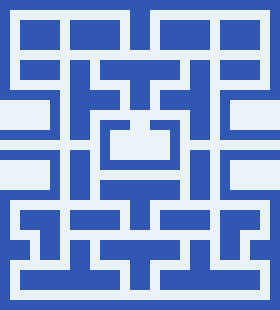

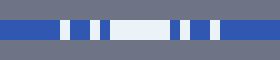

In [11]:
csg_xy_png, csg_xz_png = make_openmc_plots(
    'csg', geometry_csg,
    csg_wall_cell, csg_open_cell,
    csg_lower_cell, csg_upper_cell,
)
display(Image(filename=str(csg_xy_png)))
display(Image(filename=str(csg_xz_png)))

### RectLattice plots

Now render the lattice geometry in a **different OpenMC process** and directory. These images should agree with the CSG images at the same resolution.

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

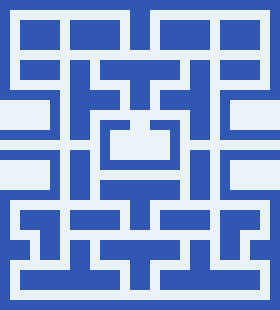

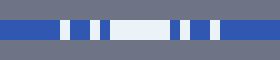

In [12]:
lattice_xy_png, lattice_xz_png = make_openmc_plots(
    'lattice', geometry_lattice,
    wall_tile_cell, open_tile_cell,
    lattice_lower_cell, lattice_upper_cell,
)
display(Image(filename=str(lattice_xy_png)))
display(Image(filename=str(lattice_xz_png)))